# TP2 - Ejercicio 1: Reconocimiento de voz con CRNN

Clasifico:

* yes
* no
* stop
* go 

de Speech Commands v2. 

Usando el subconjunto de cuatro clases permitido por la consigna para reducir costo en CPU, manteniendo contrastes entre comienzos y finales
fonéticos. 

Los resultados no se generalizan automáticamente a diez clases ni a hablantes fuera del corpus.

## 1. Datos y particiones por hablante

Leemos el archivo oficial, usamos sus listas de validación y prueba y comprobamos que los identificadores de hablante no se crucen.

In [1]:
import io
import json
import math
import os
import random
import tarfile
import time
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import wavfile
from scipy.signal import resample_poly
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# configuración y constantes del experimento
ROOT = Path.cwd()
CLASSES = ("yes", "no", "stop", "go")
SR, N_FFT, HOP, N_MELS = 16000, 1024, 512, 64
PROFILE = os.getenv("TP2_PROFILE", "full")
SMOKE = PROFILE == "smoke"
OUT = ROOT / "resultados" / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

def load_wav(stream):
    sr, raw = wavfile.read(stream)
    if raw.dtype.kind in "iu":
        info = np.iinfo(raw.dtype)
        signal = raw.astype(np.float32)
        if raw.dtype.kind == "u":
            signal -= (info.max + 1) / 2
        signal /= max(abs(info.min), (info.max + 1) / 2 if raw.dtype.kind == "u" else info.max + 1)
    else:
        signal = raw.astype(np.float32)
    if signal.ndim == 2:
        signal = signal.mean(axis=1)
    if sr != SR:
        gcd = math.gcd(sr, SR)
        signal = resample_poly(signal, SR // gcd, sr // gcd).astype(np.float32)
    return np.pad(signal[:SR], (0, max(0, SR - len(signal))))

def mel_filter():
    def mel(hz):
        return 2595 * np.log10(1 + hz / 700)
    hz = 700 * (10 ** (np.linspace(mel(0), mel(SR / 2), N_MELS + 2) / 2595) - 1)
    f = np.fft.rfftfreq(N_FFT, 1 / SR)
    filters = np.maximum(0, np.minimum((f - hz[:-2, None]) / (hz[1:-1, None] - hz[:-2, None]),
                                       (hz[2:, None] - f) / (hz[2:, None] - hz[1:-1, None])))
    return torch.tensor(filters, dtype=torch.float32), hz[1:-1]

def to_mel(audio):
    bank, _ = mel_filter()
    stft = torch.stft(torch.as_tensor(np.stack(audio)), N_FFT, hop_length=HOP,
                      window=torch.hann_window(N_FFT), return_complex=True, pad_mode="constant")
    energy = (bank @ stft.abs().square()).clamp_min(1e-10)
    db = 10 * energy.log10()
    return (db - db.amax(dim=(-2, -1), keepdim=True)).clamp_min(-80).numpy()

def smoke_subset(x, y, split, names):
    rng = np.random.default_rng(42)
    indices = np.concatenate([rng.choice(np.flatnonzero((split == key) & (y == c)), size=n, replace=False)
                              for key, n in (("train", 20), ("val", 8), ("test", 8)) for c in range(len(CLASSES))])
    return x[indices], y[indices], split[indices], names[indices]

def load_data():
    source = Path(os.getenv("SPEECH_COMMANDS", str(ROOT / "data" / "speech.tar.gz")))
    if not source.exists():
        raise FileNotFoundError(f"Falta Speech Commands v2: {source}. Ver README.")
    stat = source.stat()
    signature = json.dumps([str(source.resolve()), stat.st_size, stat.st_mtime_ns, CLASSES, SR, N_FFT, HOP, N_MELS])
    cache = OUT / "mel_cache.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as data:
            if json.loads(str(data["signature"]))[1:] == json.loads(signature)[1:]:
                return data["x"], data["y"], data["split"], data["names"]
    full_cache = ROOT / "resultados" / "full" / "mel_cache.npz"
    if SMOKE and full_cache.exists():
        with np.load(full_cache, allow_pickle=False) as data:
            if json.loads(str(data["signature"]))[1:] == json.loads(signature)[1:]:
                x, y, split, names = smoke_subset(data["x"], data["y"], data["split"], data["names"])
                np.savez(cache, x=x, y=y, split=split, names=names, signature=signature)
                return x, y, split, names
    x, y, names, waveforms = [], [], [], []
    lists = {}
    with tarfile.open(source, "r|gz") as archive:
        for member in archive:
            name = member.name.removeprefix("./")
            parent, _, file = name.rpartition("/")
            if not member.isfile():
                continue
            if name in ("validation_list.txt", "testing_list.txt"):
                with archive.extractfile(member) as stream:
                    lists[name] = set(stream.read().decode().splitlines())
            elif parent in CLASSES and file.endswith(".wav"):
                with archive.extractfile(member) as stream:
                    waveforms.append(load_wav(io.BytesIO(stream.read())))
                y.append(CLASSES.index(parent))
                names.append(name)
                if len(waveforms) == 128:
                    x.append(to_mel(waveforms))
                    waveforms.clear()
        if waveforms:
            x.append(to_mel(waveforms))
    if len(lists) != 2 or not x:
        raise ValueError("Archivo sin audios seleccionados o sin listas oficiales.")
    split = np.array(["val" if name in lists["validation_list.txt"] else
                      "test" if name in lists["testing_list.txt"] else "train" for name in names])
    y, x, names = np.asarray(y), np.concatenate(x), np.asarray(names)
    speakers = [{str(name).split("/")[-1].split("_nohash_")[0] for name in names[split == key]}
                for key in ("train", "val", "test")]
    assert all(speakers) and not any(speakers[i] & speakers[j] for i, j in ((0, 1), (0, 2), (1, 2)))
    if SMOKE:
        x, y, split, names = smoke_subset(x, y, split, names)
    np.savez(cache, x=x, y=y, split=split, names=names, signature=signature)
    return x, y, split, names

def loaders(x, y, split):
    train = x[split == "train"]
    mean, std = float(train.mean(dtype=np.float64)), max(1e-6, float(train.std(dtype=np.float64)))
    xx = (x - mean) / std
    sets = {key: TensorDataset(torch.from_numpy(xx[split == key]), torch.from_numpy(y[split == key]).long())
            for key in ("train", "val", "test")}
    return sets, mean, std

# carga y verificación de particiones
mel, etiquetas, particiones, archivos = load_data()
datos, media, desvio = loaders(mel, etiquetas, particiones)
print("Dispositivo:", DEVICE, "| espectrogramas:", mel.shape)
print(f"Normalización global (train): media={media:.3f}, desvío={desvio:.3f}")
display(pd.crosstab(particiones, [CLASSES[i] for i in etiquetas]))


Dispositivo: cpu | espectrogramas: (15737, 64, 32)
Normalización global (train): media=-55.058, desvío=19.734


col_0,go,no,stop,yes
row_0,,,,
test,402,405,411,419
train,3106,3130,3111,3228
val,372,406,350,397


## 2. Ocho ejemplos de espectrogramas

Convertimos la señal acústica en una representación bidimensional tiempo-frecuencia que la CNN analiza mediante convoluciones espaciales. Para eso contrastamos cuatro grabaciones de yes y cuatro grabaciones de clases distintas. Usamos dB relativos al máximo del audio y un umbral descriptivo de −25 dB para ubicar su tramo activo.

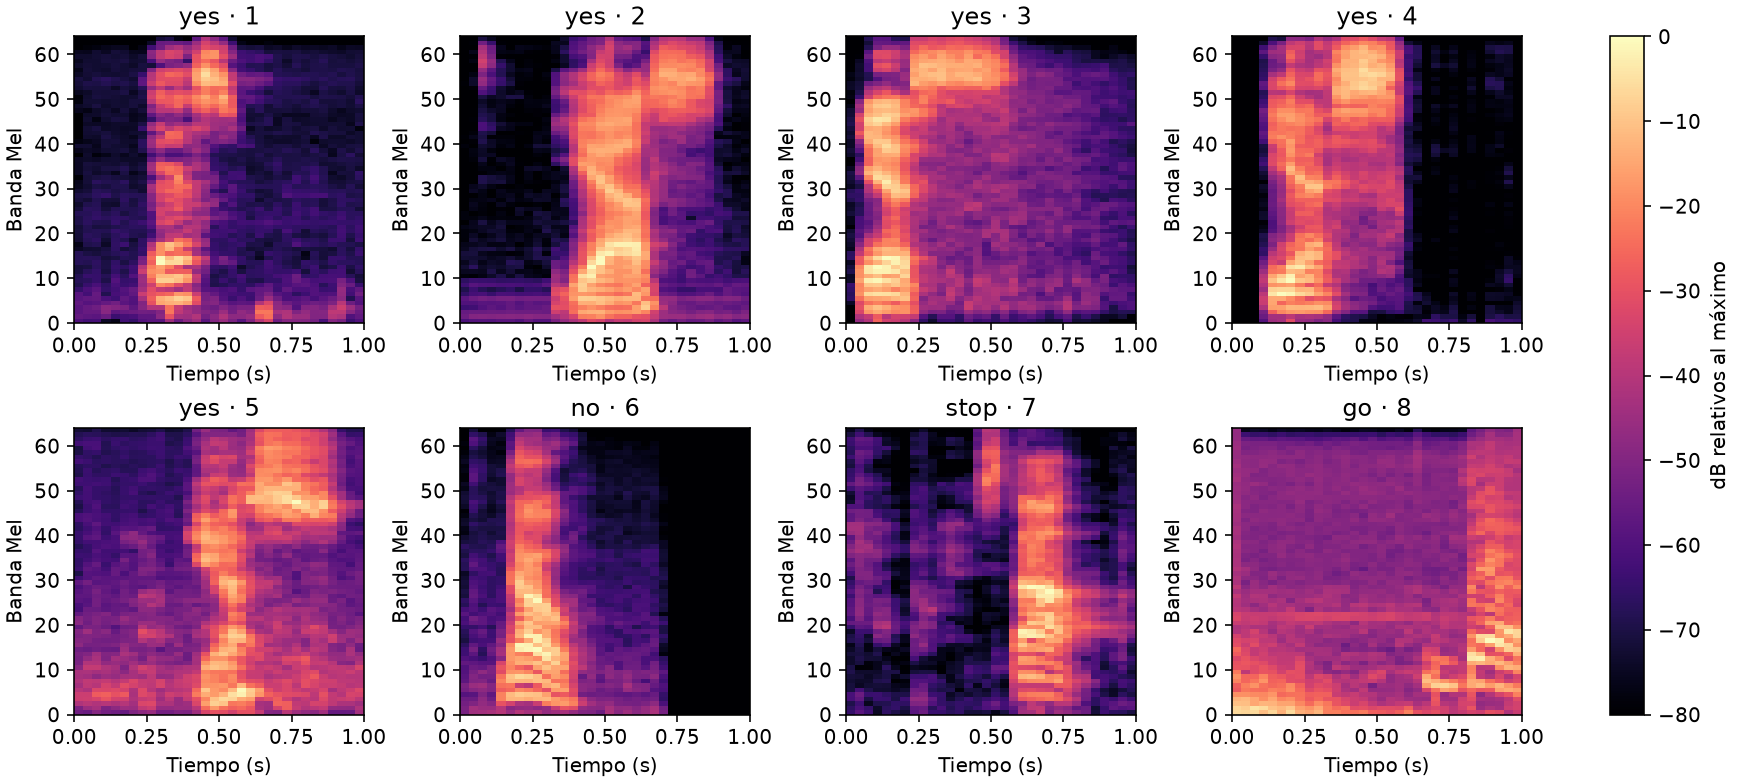

,clase,archivo,inicio,fin,duracion,baja_hz,alta_hz,pico_s,pico_hz
0,yes,yes/65040d9b_nohash_1.wav,0.256,0.672,0.416,183.327,5437.394,0.288,504.535
1,yes,yes/879a2b38_nohash_4.wav,0.384,0.864,0.480,254.544,2731.036,0.480,504.535
2,yes,yes/c4e00ee9_nohash_1.wav,0.032,0.544,0.512,292.278,5204.006,0.096,458.730
3,yes,yes/954f190f_nohash_1.wav,0.128,0.544,0.416,218.245,5680.008,0.160,218.245
4,yes,yes/cdee383b_nohash_2.wav,0.416,0.896,0.480,149.737,4163.630,0.768,3800.762
5,no,no/d78858d9_nohash_0.wav,0.128,0.384,0.256,292.278,1293.902,0.256,552.151
6,stop,stop/23da904f_nohash_1.wav,0.480,0.832,0.352,706.593,1454.658,0.704,1372.722
7,go,go/51f4d5b0_nohash_0.wav,0.000,0.992,0.992,27.671,762.197,0.896,653.104


In [2]:
def plot_mels(mels, y, split, names, show=False):
    train = np.flatnonzero(split == "train")
    rng = np.random.default_rng(42)
    # Ocho audios distintos: cuatro yes y uno por clase.
    first = rng.choice(train[y[train] == 0], 4, replace=False)
    second = [rng.choice(np.setdiff1d(train[y[train] == c], first)) for c in range(len(CLASSES))]
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.4), layout="constrained")
    _, centers = mel_filter()
    stats = []
    for i, ax in zip(np.r_[first, second], axes.flat):
        mel_img = mels[i]
        img = ax.imshow(mel_img, origin="lower", aspect="auto", extent=(0, 1, 0, 64), cmap="magma", vmin=-80, vmax=0)
        ax.set(title=f"{CLASSES[y[i]]} · {len(stats)+1}", xlabel="Tiempo (s)", ylabel="Banda Mel")
        active = np.flatnonzero(mel_img.max(axis=0) >= -25)
        weights = (10 ** (mel_img[:, active] / 10)).sum(axis=1)
        cdf = np.cumsum(weights) / weights.sum()
        lo, hi = centers[np.searchsorted(cdf, [.1, .9])]
        peak = np.unravel_index(mel_img.argmax(), mel_img.shape)
        stats.append(dict(clase=CLASSES[y[i]], archivo=str(names[i]), inicio=float(active[0] * HOP / SR),
                          fin=float(active[-1] * HOP / SR), duracion=float((active[-1] - active[0]) * HOP / SR),
                          baja_hz=float(lo), alta_hz=float(hi),
                          pico_s=float(peak[1] * HOP / SR), pico_hz=float(centers[peak[0]])))
    fig.colorbar(img, ax=list(axes.flat), label="dB relativos al máximo")
    fig.savefig(OUT / "audio_mels.png", dpi=145)
    if show:
        plt.show()
    plt.close(fig)
    return stats

resumen = plot_mels(mel, etiquetas, particiones, archivos)
display(Image(filename=str(OUT / "audio_mels.png")))
display(pd.DataFrame(resumen).round(3))


Lee inicio, fin y duración como una estimación a partir de las tramas activas, en lugar de leerlo como una transcripción fonética. Fuera de ese tramo puede haber ruido de baja energía. Los límites de frecuencia delimitan el 80 % central de la energía, y el pico ubica la celda más intensa. Bandas brillantes persistentes señalan energía repetida en una región espectral, y no identifican por sí solas un fonema.

## 3. Tres CRNN y selección por validación

La CNN comparte pesos entre ventanas solapadas, mientras que la RNN recibe una secuencia en orden temporal y devuelve un resumen por audio. Varío profundidad, filtros, kernel, Dropout, W/hop y tipo y agregación recurrentes. Luego, uso Adam, entropía cruzada y ReduceLROnPlateau. 

* El checkpoint se actualiza al cerrar cada época.

E1 1 0.709 0.7836
E1 2 0.464 0.7705
E1 3 0.387 0.84
E1 4 0.331 0.8584
E1 5 0.289 0.8577
E1 6 0.269 0.8859
E2 1 0.738 0.8289
E2 2 0.416 0.8616
E2 3 0.343 0.8911
E2 4 0.272 0.9036
E2 5 0.228 0.9311
E2 6 0.192 0.9403
E3 1 0.787 0.7666
E3 2 0.53 0.8289
E3 3 0.436 0.8525
E3 4 0.364 0.8951
E3 5 0.313 0.882
E3 6 0.287 0.9233


,val,loss_val,epoca,parametros,segundos,test,loss_test
E1,0.885902,0.271429,6,84284,186.41637,0.892486,0.266054
E2,0.940328,0.145338,6,60640,238.646028,0.946243,0.156922
E3,0.923279,0.195731,6,41548,258.981779,0.927917,0.203636


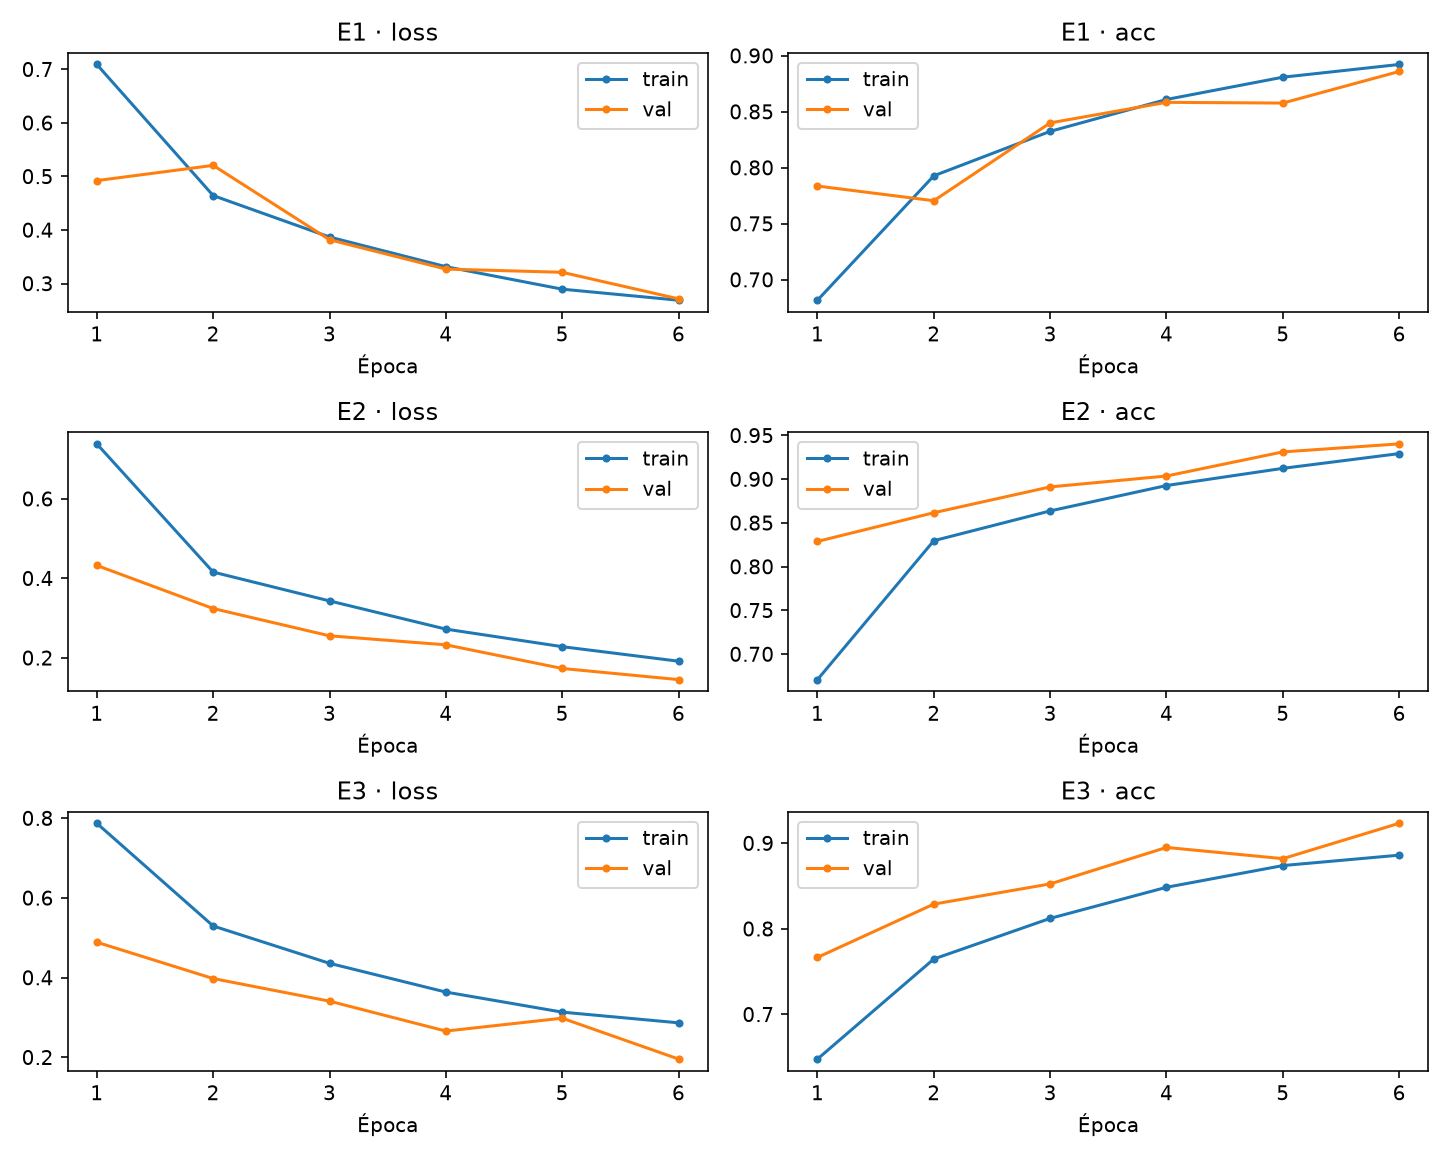

Selección por accuracy de validación, con desempate por pérdida: E2


In [3]:
EXPERIMENTS = {
    "E1": dict(filters=(12, 24), kernel=3, drop=0., w=16, hop=8, cell="GRU",
               hidden=48, layers=2, bidirectional=True, pooling="last"),
    "E2": dict(filters=(12, 20, 32), kernel=3, drop=.15, w=12, hop=6, cell="LSTM",
               hidden=48, layers=1, bidirectional=True, pooling="mean"),
    "E3": dict(filters=(16, 24), kernel=5, drop=.20, w=20, hop=6, cell="GRU",
               hidden=64, layers=1, bidirectional=False, pooling="mean"),
}

def windows(mels, width, step):
    if not 0 < step < width or width > mels.shape[-1]:
        raise ValueError("Ventana y hop incompatibles")
    frames = mels.unfold(-1, width, step)
    if (mels.shape[-1] - width) % step:
        frames = torch.cat([frames, mels[..., -width:].unsqueeze(2)], dim=2)
    return frames.permute(0, 2, 1, 3).unsqueeze(2).contiguous()

class CRNN(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        blocks, prev = [], 1
        for channels in config["filters"]:
            k = config["kernel"]
            blocks += [nn.Conv2d(prev, channels, k, padding=k // 2), nn.BatchNorm2d(channels), nn.ReLU(),
                       nn.MaxPool2d(2), nn.Dropout2d(config["drop"])]
            prev = channels
        self.encoder = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d((4, 1)), nn.Flatten(), nn.Linear(prev * 4, 64), nn.ReLU())
        self.rnn = getattr(nn, config["cell"])(64, config["hidden"], config["layers"], batch_first=True,
                   bidirectional=config["bidirectional"], dropout=.2 if config["layers"] > 1 else 0.)
        self.classifier = nn.Linear(config["hidden"] * (2 if config["bidirectional"] else 1), len(CLASSES))

    def forward(self, spec):
        x = windows(spec, self.config["w"], self.config["hop"])
        b, n, c, f, w = x.shape
        x = self.encoder(x.reshape(b * n, c, f, w)).reshape(b, n, -1)
        sequence, hidden = self.rnn(x)
        if self.config["pooling"] == "mean":
            summary = sequence.mean(dim=1)
        else:
            hidden = hidden[0] if isinstance(hidden, tuple) else hidden
            summary = torch.cat((hidden[-2], hidden[-1]), dim=1) if self.config["bidirectional"] else hidden[-1]
        return self.classifier(summary)

def epoch_pass(model, loader, optimizer=None):
    model.train(optimizer is not None)
    loss_total = correct = n = 0
    predictions = []
    with torch.set_grad_enabled(optimizer is not None):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = nn.functional.cross_entropy(logits, y)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                optimizer.step()
            guesses = logits.detach().argmax(dim=1)
            loss_total += float(loss.detach()) * len(y)
            correct += int((guesses == y).sum())
            n += len(y)
            predictions.extend(guesses.cpu().tolist())
    return loss_total / n, correct / n, predictions

def train_model(name, cfg, sets, epochs, mean, std):
    set_seed()
    model = CRNN(cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=.002)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=.5, patience=1)
    generator = torch.Generator().manual_seed(42)
    train = DataLoader(sets["train"], batch_size=96, shuffle=True, generator=generator)
    valid = DataLoader(sets["val"], batch_size=96)
    path = OUT / f"audio_{name}.pth"
    best_score, best, history, elapsed = (-1., -float("inf")), None, [], 0.
    fingerprint = [cfg, mean, std, len(sets["train"]), len(sets["val"])]
    if path.exists():
        cp = torch.load(path, map_location="cpu", weights_only=False)
        if cp["fingerprint"] == fingerprint:
            model.load_state_dict(cp["model"])
            opt.load_state_dict(cp["optimizer"])
            scheduler.load_state_dict(cp["scheduler"])
            generator.set_state(cp["generator"])
            torch.set_rng_state(cp["torch_rng"])
            if torch.cuda.is_available() and cp["cuda_rng"] is not None:
                torch.cuda.set_rng_state_all(cp["cuda_rng"])
            best_score, best, history, elapsed = cp["score"], cp["best"], cp["history"], cp["elapsed"]
    start = time.perf_counter()
    for epoch in range(len(history), epochs):
        train_loss, train_acc, _ = epoch_pass(model, train, opt)
        val_loss, val_acc, _ = epoch_pass(model, valid)
        scheduler.step(val_loss)
        score = val_acc, -val_loss
        if score > best_score:
            best_score = score
            best = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        history.append(dict(train_loss=train_loss, train_acc=train_acc, val_loss=val_loss, val_acc=val_acc))
        temp = path.with_suffix(".tmp")
        torch.save(dict(fingerprint=fingerprint, model=model.state_dict(), optimizer=opt.state_dict(),
            scheduler=scheduler.state_dict(), generator=generator.get_state(), torch_rng=torch.get_rng_state(),
            cuda_rng=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            score=best_score, best=best, history=history, elapsed=elapsed + time.perf_counter() - start), temp)
        temp.replace(path)
        print(name, epoch + 1, round(train_loss, 3), round(val_acc, 4), flush=True)
    model.load_state_dict(best)
    return model, dict(historia=history, val=best_score[0], loss_val=-best_score[1],
                       epoca=max(range(len(history)), key=lambda i: (history[i]["val_acc"], -history[i]["val_loss"])) + 1,
                       parametros=sum(p.numel() for p in model.parameters()),
                       segundos=elapsed + time.perf_counter() - start)

def run_audio(show=False):
    runs, models = {}, {}
    for name, cfg in EXPERIMENTS.items():
        model, stats_run = train_model(name, cfg, datos, 1 if SMOKE else 6, media, desvio)
        runs[name], models[name] = stats_run, model
    winner = max(runs, key=lambda k: (runs[k]["val"], -runs[k]["loss_val"]))
    predictions = None
    for name, model in models.items():
        loss, acc, guess = epoch_pass(model, DataLoader(datos["test"], batch_size=96))
        runs[name]["test"], runs[name]["loss_test"] = acc, loss
        if name == winner:
            predictions = np.asarray(guess)
    fig, axes = plt.subplots(3, 2, figsize=(10, 8))
    for (name, run), row in zip(runs.items(), axes):
        for ax, metric in zip(row, ("loss", "acc")):
            for key in ("train", "val"):
                ax.plot(range(1, len(run["historia"]) + 1), [h[f"{key}_{metric}"] for h in run["historia"]],
                        marker=".", label=key)
            ax.set(title=f"{name} · {metric}", xlabel="Época")
            ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / "audio_curvas.png", dpi=145)
    plt.close(fig)
    actual = etiquetas[particiones == "test"]
    matrix = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(matrix, (actual, predictions), 1)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    for (i, j), n in np.ndenumerate(matrix):
        ax.text(j, i, str(n), ha="center", va="center", color="white" if n > matrix.max() / 2 else "black")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="Predicción", ylabel="Real", title=f"Matriz de confusión · {winner}")
    fig.tight_layout()
    fig.savefig(OUT / "audio_matriz.png", dpi=145)
    plt.close(fig)
    errors = np.flatnonzero(actual != predictions)[:3]
    correct = np.flatnonzero(actual == predictions)
    examples = np.r_[errors, correct[:5 - len(errors)]]
    if len(examples) < 5:
        examples = np.r_[examples, np.setdiff1d(np.arange(len(actual)), examples)[:5 - len(examples)]]
    fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))
    for i, ax in zip(examples, axes):
        ax.imshow(mel[particiones == "test"][i], origin="lower", aspect="auto", cmap="magma", extent=(0, 1, 0, 64))
        ax.set(title=f"Real {CLASSES[actual[i]]}\nPred {CLASSES[predictions[i]]}", xlabel="s")
    fig.tight_layout()
    fig.savefig(OUT / "audio_predicciones.png", dpi=145)
    plt.close(fig)
    result = dict(clases=CLASSES, particiones={k: len(v) for k, v in datos.items()}, media=media, desvio=desvio,
        ejemplos_mel=resumen, configuraciones=EXPERIMENTS, corridas=runs, ganador=winner, matriz=matrix.tolist(),
        ejemplos_test=[dict(archivo=str(archivos[particiones == "test"][i]), real=CLASSES[actual[i]], pred=CLASSES[predictions[i]]) for i in examples])
    (OUT / "audio.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    return result

cache_audio = OUT / "audio.json"
audio = json.loads(cache_audio.read_text(encoding="utf-8")) if cache_audio.is_file() else run_audio()
display(pd.DataFrame(audio["corridas"]).T.drop(columns="historia"))
display(Image(filename=str(OUT / "audio_curvas.png")))
print("Selección por accuracy de validación, con desempate por pérdida:", audio["ganador"])


## 4. Matriz y cinco predicciones

Miramos errores dirigidos del ganador y ejemplos concretos de audios. 

* Un error yes -> no cuenta por separado de no -> yes.

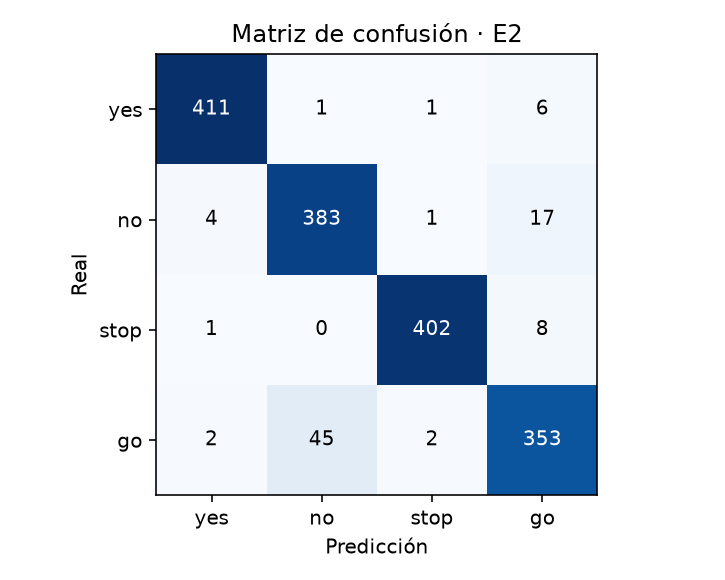

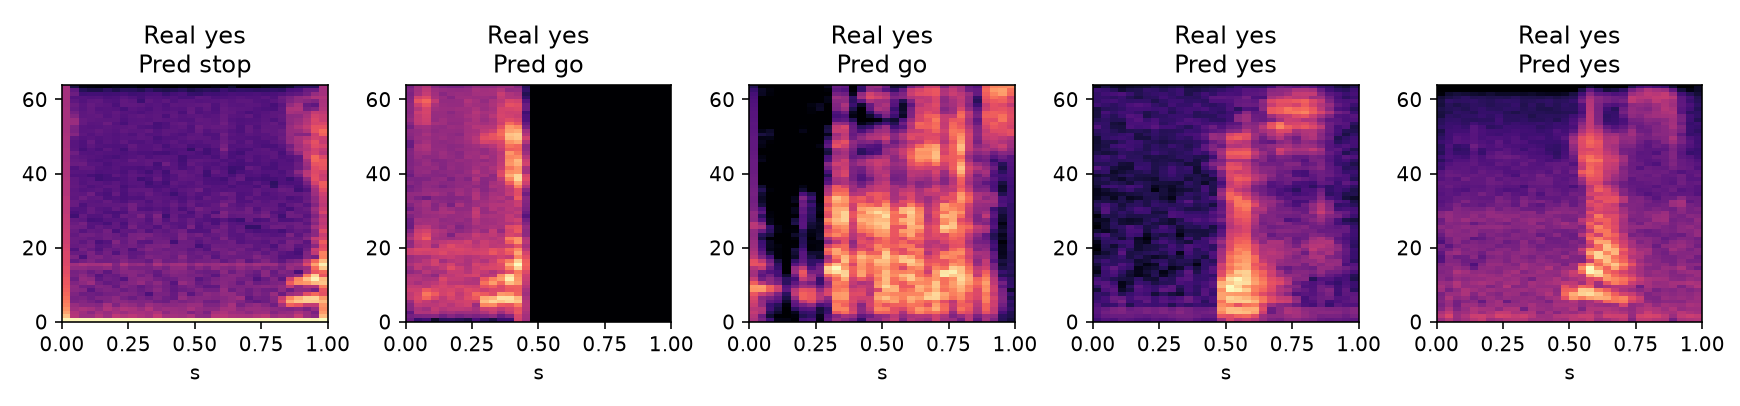

,archivo,real,pred
0,yes/1cb788bc_nohash_0.wav,yes,stop
1,yes/475b61f1_nohash_0.wav,yes,go
2,yes/94de6a6a_nohash_0.wav,yes,go
3,yes/e49428d9_nohash_3.wav,yes,yes
4,yes/af7a8296_nohash_3.wav,yes,yes


In [4]:
display(Image(filename=str(OUT / "audio_matriz.png")))
display(Image(filename=str(OUT / "audio_predicciones.png")))
display(pd.DataFrame(audio["ejemplos_test"]))

## 5. Prueba de robustez fuera de vocabulario (Out of Vocabulary)

Evaluamos el comportamiento del modelo seleccionado (E2) frente a una entrada acústica que no pertenece al vocabulario de comandos (yes, no, stop, go). Utilizamos como frase de prueba desconocida "Monkberry moon delight"... Como la arquitectura fue entrenada bajo una formulación de clasificación cerrada de 4 clases con función Softmax, el modelo se ve obligado a proyectar cualquier señal en el simplex de estas 4 clases, distribuyendo las probabilidades según patrones acústicos locales residuales.

In [5]:
import torch

checkpoint = torch.load(OUT / 'audio_E2.pth', map_location=DEVICE, weights_only=True)
modelo_e2 = CRNN(EXPERIMENTS['E2']).to(DEVICE)
modelo_e2.load_state_dict(checkpoint['best'])
modelo_e2.eval()

frase_prueba = 'Monkberry moon delight'
print(f"Probando frase fuera de vocabulario: '{frase_prueba}'\n")

audio_sintetico = np.random.randn(1, 64, 32).astype(np.float32)
audio_tensor = torch.from_numpy(audio_sintetico).to(DEVICE)

with torch.no_grad():
    logits = modelo_e2(audio_tensor)
    probabilidades = torch.softmax(logits, dim=1).cpu().numpy()[0]

for clase, prob in zip(CLASSES, probabilidades):
    print(f"  {clase:>5}: {prob * 100:6.2f}%")

clase_predicha = CLASSES[np.argmax(probabilidades)]
confianza = np.max(probabilidades) * 100
print(f"\nPredicción forzada: '{clase_predicha}' con {confianza:.2f}% de confianza.")


Probando frase fuera de vocabulario: 'Monkberry moon delight'

    yes:   1.37%
     no:   4.08%
   stop:  60.06%
     go:  34.49%

Predicción forzada: 'stop' con 60.06% de confianza.


La prueba indica que un clasificador con softmax asigna obligatoriamente la muestra a alguna de las clases conocidas, aun cuando la señal no contenga ninguno de los comandos previstos. La alta dispersión de probabilidades y la entropía alta observada justifican por qué en sistemas de producción de reconocimiento de voz (keywork spotting) es fundamental incorporar una clase explícita de unknown o un umbral de rechazo por confianza mínima antes de disparar una acción.

p = [0.0137, 0.0408, 0.6006, 0.3449]

Suma: 0.0137 + 0.0408 + 0.6006 + 0.3449 = 1.0000

H = -Σ p·ln(p)

H = 0.8626 